# Weather Trend Forecasting
## Notebook 01: Data Cleaning

## About PM Accelerator

**Product Manager Accelerator**  
Boston, MA, founded 2020  
pmaccelerator.io | linkedin.com/school/pmaccelerator

The Product Manager Accelerator Program supports product managers through every stage of their careers, from students looking for their first PM job to directors moving into leadership roles, and has helped hundreds of people reach their career goals. Its programs include:

- PMA Pro: end-to-end PM job hunting, with FAANG-level PM skills, unlimited mock interviews and referrals through its alumni network
- AI PM Bootcamp: build a real AI product with a team of AI engineers, data scientists and designers, and launch it to real users
- PMA Power Skills: sharpens PM, leadership and executive presentation skills for working PMs
- PMA Leader: helps PMs get promoted to director and product executive levels
- 1:1 Resume Review: PM resume rewrites with an interview guarantee

It also publishes hundreds of free PM training videos and courses on YouTube.

## What this notebook does

Input: the raw Kaggle file `data/GlobalWeatherRepository.csv` (never edited).
Output: `data/processed/weather_clean.csv`, one row per location per day.

Steps:
1. Load and profile the raw data
2. Parse the time columns
3. Keep the locations that were tracked over the whole period
4. Remove duplicate location-days
5. Drop redundant unit columns
6. Treat placeholder values (-9999) and negative concentrations
7. Treat physically impossible values (before and after)
8. Look at the July 2026 pressure change
9. Look at the snapshot time drift
10. Fill the gaps created by cleaning, using past values only
11. Add derived columns (continent, hemisphere, local hour)
12. Normalization: which columns and why
13. Save, and a summary of every assumption

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler

RAW = Path('../data/GlobalWeatherRepository.csv')
OUT = Path('../data/processed/weather_clean.csv')
FIG = Path('../reports/figures')
FIG.mkdir(parents=True, exist_ok=True)
OUT.parent.mkdir(parents=True, exist_ok=True)

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 50)
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': '#e5e4e0', 'grid.linewidth': 0.6,
    'axes.edgecolor': '#8a8984', 'axes.titleweight': 'bold',
})
PALETTE = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300']
CITIES = ['Moscow', 'London', 'New Delhi', 'Singapore', 'Canberra', 'Buenos Aires']

def save(fig, name):
    fig.savefig(FIG / name)
    print('saved', FIG / name)

## 1. Load and profile the raw data

In [2]:
raw = pd.read_csv(RAW)
print('rows, columns:', raw.shape)
raw.head(3).T

rows, columns: (170928, 41)


,0,1,2
country,Afghanistan,Albania,Algeria
location_name,Kabul,Tirana,Algiers
latitude,34.52,41.33,36.76
longitude,69.18,19.82,3.05
timezone,Asia/Kabul,Europe/Tirane,Africa/Algiers
last_updated_epoch,1715849100,1715849100,1715849100
last_updated,2024-05-16 13:15,2024-05-16 10:45,2024-05-16 09:45
temperature_celsius,26.6,19.0,23.0
temperature_fahrenheit,79.8,66.2,73.4
condition_text,Partly Cloudy,Partly cloudy,Sunny


In [3]:
print('missing values (NaN) in the whole table:', raw.isna().sum().sum())
print('fully duplicated rows:', raw.duplicated().sum())
raw.dtypes.value_counts()

missing values (NaN) in the whole table: 0
fully duplicated rows: 0


float64    23
str        11
int64       7
Name: count, dtype: int64

There are no NaN values, but that does not mean nothing is missing. Missing air quality readings are stored as the number -9999 (section 6).

## 2. Time columns

`last_updated` is in each city's local time, so it cannot be used to order rows across cities.
`last_updated_epoch` is a UTC timestamp, so it is the one used for ordering and for the daily date.
The local time is kept because the local hour of the snapshot matters for temperature (section 9).

In [4]:
df = raw.copy()
df['time_utc'] = pd.to_datetime(df['last_updated_epoch'], unit='s')
df['time_local'] = pd.to_datetime(df['last_updated'])
df['date'] = df['time_utc'].dt.normalize()

print('first snapshot (UTC):', df['time_utc'].min())
print('last snapshot (UTC): ', df['time_utc'].max())
print('days covered:', df['date'].nunique())
print('raw country values:', df['country'].nunique())
print('raw country + location pairs:', df.groupby(['country', 'location_name']).ngroups)

first snapshot (UTC): 2024-05-16 08:45:00
last snapshot (UTC):  2026-10-13 05:45:00
days covered: 879
raw country values: 211
raw country + location pairs: 286


## 3. Keep the locations tracked over the whole period

The dataset is meant to hold one capital per country, observed once a day.
In practice some country + location pairs appear only a handful of times. Most of these are
the same capital with the country name in another language (for example `Inde`, `Польша`, `Saudi Arabien`)
or a wrong geocoding match. They cannot form a time series.

Rule: keep a country + location pair only if it has at least 500 daily rows (more than half of the period).

In [5]:
rows_per_loc = df.groupby(['country', 'location_name']).size().rename('rows')
print(pd.cut(rows_per_loc, [0, 10, 100, 499, 1000]).value_counts().sort_index())

rows
(0, 10]         47
(10, 100]       29
(100, 499]      25
(499, 1000]    185
Name: count, dtype: int64


In [6]:
keep = rows_per_loc[rows_per_loc >= 500].index
dropped = rows_per_loc[rows_per_loc < 500].sort_values(ascending=False)

before_rows = len(df)
df = df.set_index(['country', 'location_name']).loc[keep].reset_index()

print('locations kept:', len(keep), '| countries kept:', df['country'].nunique())
print('locations dropped:', len(dropped), '| rows dropped:', before_rows - len(df))
dropped.head(15)

locations kept: 185 | countries kept: 178
locations dropped: 101 | rows dropped: 9180


country        location_name    
Madagascar     Ivory                458
Costa Rica     San Ignacio          439
Belgium        'S Gravenjansdijk    431
Iceland        Vestmannaeyjar       424
Cameroon       Ngaoundere           424
Myanmar        Yangon               424
Paraguay       Aurora               423
Jamaica        Port Royal           420
Bulgaria       Lom                  417
Cote d'Ivoire  Yamoussoukro         416
Vietnam        Ban Lom              411
Palau          Airai                371
               Koror                338
Jamaica        Kingston             333
Belgium        'S-Gravenbrakel      324
Name: rows, dtype: int64

In [7]:
dropped.tail(10)

country                          location_name     
Kuwait                           Kuwait                1
Letonia                          Riga                  1
Malásia                          Ivory Ivory Ban       1
Marrocos                         Morocco City          1
Philippines                      Kiyabo                1
Polônia                          Moldova               1
Russia                           Saint Petersburg      1
Saint-Vincent-et-les-Grenadines  Kingstown             1
San Marino                       City Of San Marino    1
火鸡                               -Kingdom              1
Name: rows, dtype: int64

A few kept locations have unusual names for their country (for example `Bulgaria / Bogot`, `Turkey / Yaren`,
`Indonesia / Laos`). Their coordinates and time zones are inside the stated country, so they are real places
with those names. They are kept as they are.

In [8]:
odd = [('Bulgaria', 'Bogot'), ('Turkey', 'Yaren'), ('Indonesia', 'Laos'), ('Iran', 'Chi Chi Khvar')]
(df.set_index(['country', 'location_name']).loc[odd]
   .groupby(level=[0, 1])[['latitude', 'longitude', 'timezone']].first())

,,latitude,longitude,timezone
country,location_name,,,
Bulgaria,Bogot,43.32,24.70,Europe/Sofia
Indonesia,Laos,-8.18,114.32,Asia/Jakarta
Iran,Chi Chi Khvar,36.26,46.59,Asia/Tehran
Turkey,Yaren,39.55,27.62,Europe/Istanbul


## 4. Duplicate location-days

Each location should have one snapshot per UTC day. A small number of location-days have two
(mostly on the first day of collection). The first snapshot of the day is kept.

In [9]:
df = df.sort_values(['country', 'location_name', 'time_utc'])
dup = df.duplicated(['country', 'location_name', 'date'])
print('duplicate location-days removed:', dup.sum())
df = df[~dup].reset_index(drop=True)
print('rows now:', len(df))

duplicate location-days removed: 187
rows now: 161561


## 5. Redundant unit columns

Every measurement is stored twice (metric and imperial). The metric version is kept and the imperial
copies are dropped. A check first confirms they hold the same information.

In [10]:
print('max |C*9/5+32 - F|:', (df['temperature_celsius'] * 9 / 5 + 32 - df['temperature_fahrenheit']).abs().max().round(2))
print('max |mm/25.4 - in|:', (df['precip_mm'] / 25.4 - df['precip_in']).abs().max().round(2))

imperial = ['temperature_fahrenheit', 'feels_like_fahrenheit', 'wind_mph', 'gust_mph',
            'pressure_in', 'precip_in', 'visibility_miles']
df = df.drop(columns=imperial)
print('columns now:', df.shape[1])

max |C*9/5+32 - F|: 0.12
max |mm/25.4 - in|: 0.01
columns now: 37


## 6. Placeholder values and negative concentrations

Air quality concentrations cannot be negative. The value -9999 is a "no reading" code, and other negative
values are errors. All of them are set to missing (NaN) and filled in section 10.

In [11]:
aq_cols = ['air_quality_Carbon_Monoxide', 'air_quality_Ozone', 'air_quality_Nitrogen_dioxide',
           'air_quality_Sulphur_dioxide', 'air_quality_PM2.5', 'air_quality_PM10']

neg = df[aq_cols] < 0
print('negative values per column:')
print(neg.sum()[neg.sum() > 0])
df.loc[neg.any(axis=1), ['country', 'location_name', 'date'] + aq_cols]

negative values per column:
air_quality_Carbon_Monoxide    1
air_quality_Sulphur_dioxide    1
air_quality_PM10               2
dtype: int64


,country,location_name,date,air_quality_Carbon_Monoxide,air_quality_Ozone,air_quality_Nitrogen_dioxide,air_quality_Sulphur_dioxide,air_quality_PM2.5,air_quality_PM10
4408,Antigua and Barbuda,Saint John's,2024-06-11,-9999.00,32.5,0.40,0.400,2.300,12.10
74254,Kiribati,Tarawa,2024-07-16,223.60,14.5,0.00,-9999.000,0.500,0.90
120831,Saudi Arabia,Riyadh,2025-02-25,432.90,81.0,23.68,28.675,639.175,-1848.15
121164,Saudi Arabia,Riyadh,2026-01-25,181.85,56.0,14.65,23.050,443.250,-998.15


In [12]:
df[aq_cols] = df[aq_cols].mask(df[aq_cols] < 0)
print('negatives left:', (df[aq_cols] < 0).sum().sum())

negatives left: 0


## 7. Physically impossible values: before and after

These are values that cannot be real readings at these locations. They are set to missing, not clipped,
because a clipped value would still be wrong.

| Column | Kept range | Reason |
|---|---|---|
| temperature_celsius | -60 to 60 | the world record high is 56.7 C |
| feels_like_celsius | -70 to 70 | same reasoning as temperature |
| wind_kph | 0 to 150 | 150 km/h is a strong hurricane, none hit these cities on those days |
| gust_kph | 0 to 200 | removed together with the matching wind value |
| pressure_mb | 950 to 1060 | the sea-level pressure range at these cities, see section 8 |

Extreme values that are physically possible (heat waves, cold snaps, heavy rain, very high PM10 during dust
storms, UV index above 11) are kept. Air quality is heavily skewed by nature, so later analyses use log
scales and rank correlations instead of removing high readings. Statistical anomalies are studied in notebook 05.

In [13]:
rules = {
    'temperature_celsius': (-60, 60),
    'feels_like_celsius': (-70, 70),
    'wind_kph': (0, 150),
    'gust_kph': (0, 200),
    'pressure_mb': (950, 1060),
}

before = df.copy()
bad = pd.DataFrame({c: ~df[c].between(lo, hi) for c, (lo, hi) in rules.items()})
bad['gust_kph'] |= bad['wind_kph']
bad['wind_kph'] |= bad['gust_kph']
bad['feels_like_celsius'] |= bad['temperature_celsius']
print('values flagged per column:')
print(bad.sum())

values flagged per column:
temperature_celsius     1
feels_like_celsius      1
wind_kph                5
gust_kph                5
pressure_mb            39
dtype: int64


In [14]:
show = ['country', 'location_name', 'date', 'temperature_celsius', 'humidity', 'wind_kph', 'gust_kph', 'pressure_mb']
before.loc[bad[['temperature_celsius', 'wind_kph']].any(axis=1), show]

,country,location_name,date,temperature_celsius,humidity,wind_kph,gust_kph,pressure_mb
25239,Burundi,Bujumbura,2024-05-21,30.0,55,258.8,266.0,1013.0
25272,Burundi,Bujumbura,2024-06-23,22.5,52,2963.2,2970.4,1014.0
47140,Ethiopia,Addis Ababa,2024-06-21,22.3,57,272.2,279.4,1025.0
47981,Fiji Islands,Suva,2024-05-19,26.0,100,172.1,179.3,1011.0
48683,Fiji Islands,Suva,2026-04-24,79.3,7,16.2,27.1,1013.0
116224,Saint Kitts and Nevis,Basseterre,2024-06-28,31.1,66,205.9,213.1,1016.0


In [15]:
for c in rules:
    df[c] = df[c].mask(bad[c])

summary = pd.DataFrame({
    'min_before': before[list(rules)].min(), 'max_before': before[list(rules)].max(),
    'min_after': df[list(rules)].min(), 'max_after': df[list(rules)].max(),
    'set_to_missing': bad.sum(),
})
summary

,min_before,max_before,min_after,max_after,set_to_missing
temperature_celsius,-29.8,79.3,-29.8,49.2,1
feels_like_celsius,-36.7,81.3,-36.7,51.2,1
wind_kph,3.6,2963.2,3.6,81.0,5
gust_kph,3.6,2970.4,3.6,97.1,5
pressure_mb,771.0,3006.0,951.0,1052.0,39


saved ../reports/figures/01_outliers_before_after.png


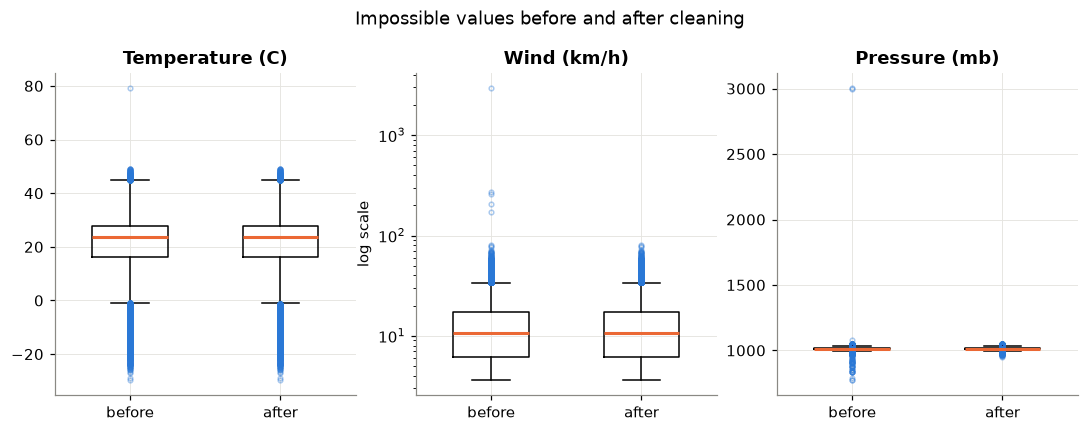

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, (c, label) in zip(axes, [('temperature_celsius', 'Temperature (C)'),
                                 ('wind_kph', 'Wind (km/h)'),
                                 ('pressure_mb', 'Pressure (mb)')]):
    ax.boxplot([before[c].dropna(), df[c].dropna()], tick_labels=['before', 'after'],
               widths=0.5, flierprops=dict(marker='o', markersize=3, alpha=0.4, markeredgecolor=PALETTE[0]),
               medianprops=dict(color=PALETTE[1], linewidth=2))
    ax.set_title(label)
    if c == 'wind_kph':
        ax.set_yscale('log')
axes[1].set_ylabel('log scale')
fig.suptitle('Impossible values before and after cleaning', y=1.03)
save(fig, '01_outliers_before_after.png')
plt.show()

The wind panel uses a log scale because one reading (2963 km/h in Bujumbura) is about 36 times the highest
remaining value (81 km/h). After cleaning, the remaining points outside the boxes are real weather extremes, not errors.

## 8. The pressure change in July 2026

Almost every pressure reading in this dataset is sea-level pressure (around 1013 mb). For a few days at the end of
July 2026, several high-altitude capitals report much lower values (770 to 890 mb). Those numbers fit the
*station* pressure at the altitude of those cities (for example about 770 mb at Addis Ababa, around 2,350 m),
not the sea-level pressure. So the data source switched the pressure definition for these cities for a short time.

These readings are not comparable with the rest. The worst ones are already set to missing by the 950 mb lower
bound in section 7. Three other readings (3000 and 3006 mb, and 1080 mb in Amman) are removed by the upper bound.

In [17]:
low = before[before['pressure_mb'] < 950]
print('readings below 950 mb by month:')
print(low.groupby(low['date'].dt.to_period('M')).size())
low.groupby('location_name')['pressure_mb'].agg(['count', 'min', 'max'])

readings below 950 mb by month:
date
2026-07    36
Freq: M, dtype: int64


,count,min,max
location_name,,,
Addis Ababa,2,771.0,771.0
Amman,1,921.0,921.0
Ankara,1,918.0,918.0
Antananarivo,2,875.0,879.0
Bujumbura,2,923.0,924.0
Damascus,1,931.0,931.0
Dushanbe,4,913.0,914.0
Gaborone,1,909.0,909.0
Guatemala City,2,849.0,851.0


saved ../reports/figures/01_pressure_change_july_2026.png


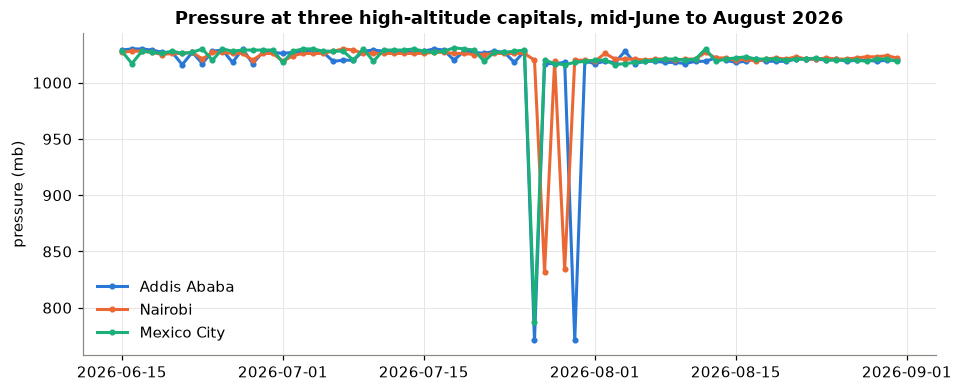

In [18]:
win = before[(before['date'] >= '2026-06-15') & (before['date'] <= '2026-08-31')]
fig, ax = plt.subplots(figsize=(10, 3.8))
for color, city in zip(PALETTE, ['Addis Ababa', 'Nairobi', 'Mexico City']):
    s = win[win['location_name'] == city].set_index('date')['pressure_mb']
    ax.plot(s.index, s.values, color=color, linewidth=2, marker='o', markersize=3, label=city)
ax.set_ylabel('pressure (mb)')
ax.set_title('Pressure at three high-altitude capitals, mid-June to August 2026')
ax.legend(frameon=False)
save(fig, '01_pressure_change_july_2026.png')
plt.show()

The change was not limited to very high cities. Between 25 and 31 July 2026, mid-altitude cities such as Sarajevo,
Santiago, Bamako and Prague also show one-day drops of 20 to 60 mb that recover the next day. Real weather does
not do that across dozens of cities in the same week, and those values stay above 950 mb, so the bound misses them.

Second rule, used only for 25 to 31 July 2026: a reading is set to missing when it is more than 10 mb below the
median of the same location's previous 7 days. It compares with past days only, so no future information is used.
The threshold of 15 mb was chosen by checking how often the same rule fires in normal summer weeks (cell below).
It is not applied to the rest of the period, because real storms (for example western Europe in January and
February 2026) also cause large drops, and those must stay.

In [19]:
past_median = (df.groupby(['country', 'location_name'])['pressure_mb']
                 .transform(lambda s: s.shift(1).rolling(7, min_periods=3).median()))
in_window = df['date'].between('2026-07-25', '2026-07-31')
drop = df['pressure_mb'] < past_median - 15
station = in_window & drop

other_summer = df['date'].dt.month.isin([6, 7, 8]) & ~in_window
weeks = df.loc[other_summer, 'date'].nunique() / 7
print('readings flagged in the July 2026 window:', station.sum())
print('same rule in other summer weeks, per week:', round((drop & other_summer).sum() / weeks, 1))

out = df.loc[station, ['location_name', 'date', 'pressure_mb']].assign(past_7day_median=past_median[station])
df.loc[station, 'pressure_mb'] = np.nan
out.sort_values('pressure_mb').head(12)

readings flagged in the July 2026 window: 39
same rule in other summer weeks, per week: 4.4


,location_name,date,pressure_mb,past_7day_median
20047,Sarajevo,2026-07-26,951.0,1019.0
31287,Santiago,2026-07-27,955.0,1018.0
20052,Sarajevo,2026-07-31,957.0,1018.0
82868,Luxembourg,2026-07-26,968.0,1021.0
53155,Tbilisi,2026-07-30,969.0,1011.0
88087,Bamako,2026-07-29,969.0,1013.0
88084,Bamako,2026-07-26,971.0,1014.0
82869,Luxembourg,2026-07-27,973.0,1021.0
63647,New Delhi,2026-07-30,975.0,1000.0
82873,Luxembourg,2026-07-31,975.0,1016.0


## 8b. A corrupted day: 17 August 2026

While building the forecasts (notebook 03), the test plots showed a one-day spike in five of the six cities on the
same date. To check this across all locations, each reading is compared with the average of the day before and the
day after, and the share of locations with a jump of more than 8 C is counted per day.

In [20]:
g = df.groupby(['country', 'location_name'])['temperature_celsius']
jump = df['temperature_celsius'] - (g.shift(1) + g.shift(-1)) / 2
by_day = pd.DataFrame({'locations': df.groupby('date').size(),
                       'share_jump_over_8C': (jump.abs() > 8).groupby(df['date']).mean().round(3)})
by_day.sort_values('share_jump_over_8C', ascending=False).head(6)

,locations,share_jump_over_8C
date,,
2024-07-21,1,1.000
2026-08-17,184,0.505
2026-08-18,184,0.207
2026-08-16,182,0.203
2026-01-02,183,0.038
2024-09-09,185,0.032


In [21]:
bad_day = pd.Timestamp('2026-08-17')
df.loc[(df['date'] == bad_day) & df['location_name'].isin(CITIES),
       ['location_name', 'date', 'temperature_celsius', 'humidity', 'condition_text']]

,location_name,date,temperature_celsius,humidity,condition_text
6072,Buenos Aires,2026-08-17,25.5,61,Clear
7825,Canberra,2026-08-17,23.1,73,Sunny
63665,New Delhi,2026-08-17,15.9,60,Sandstorm
115246,Moscow,2026-08-17,-0.3,88,Blowing snow
125748,Singapore,2026-08-17,35.9,40,Overcast
152762,London,2026-08-17,-2.0,67,Blizzard


On 17 August 2026 about half of all locations jump by more than 8 C for one day and come back the next day.
The condition labels are impossible for the season: "Blizzard" in London and "Blowing snow" in Moscow in August,
"Sandstorm" in New Delhi. The days next to it (16 and 18 August) only show up because they are compared with the
17th. (The day 2024-07-21 has a single reading, so its share is not meaningful.)

Decision: every row of 17 August 2026 is removed. This was found by looking at the data, not by a general rule,
and the date falls in the forecasting test window, so it is stated here openly. Removing it makes the test window
one day shorter; it does not change which model is chosen, because model choices are made on the validation window.

In [22]:
removed = (df['date'] == bad_day).sum()
df = df[df['date'] != bad_day].reset_index(drop=True)
print('rows removed for 17 August 2026:', removed, '| rows now:', len(df))

rows removed for 17 August 2026: 184 | rows now: 161377


## 9. Snapshot time drift

Each location is observed once a day, but the time of the snapshot is not fixed. The collection time moved
earlier by about 6 hours between 2024 and 2026. A temperature reading at 8 am and one at 2 am are not
comparable, so part of any change between years would come from the clock, not the climate.

How this is handled:
- the local hour of each snapshot is kept as a column (`local_hour`), so the models can use it as a feature
- trends across years are described with this caveat
- seasonal comparisons are made within the same months, where the drift is small

Canberra's line jumps in mid-2024 only because its snapshot crossed midnight (00:30 is one hour after 23:30).

saved ../reports/figures/01_snapshot_hour_drift.png


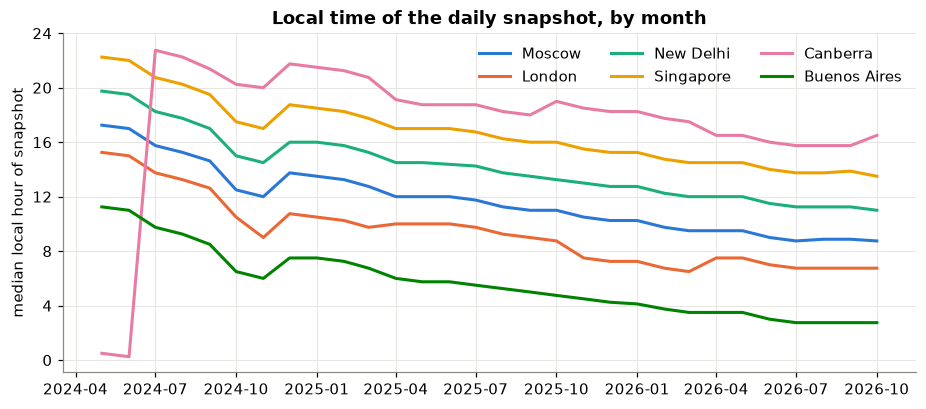

date,2024,2025,2026
location_name,,,
Buenos Aires,9.0,5.8,3.2
Canberra,21.5,18.8,16.5
London,13.0,9.8,7.0
Moscow,15.0,11.8,9.2
New Delhi,17.5,14.2,11.8
Singapore,20.0,16.8,14.2


In [23]:
df['local_hour'] = df['time_local'].dt.hour + df['time_local'].dt.minute / 60

drift = (df[df['location_name'].isin(CITIES)]
         .groupby(['location_name', df['date'].dt.to_period('M')])['local_hour'].median()
         .unstack(0)[CITIES])
drift.index = drift.index.to_timestamp()

fig, ax = plt.subplots(figsize=(10, 4))
for color, city in zip(PALETTE, CITIES):
    ax.plot(drift.index, drift[city], color=color, linewidth=2, label=city)
ax.set_ylabel('median local hour of snapshot')
ax.set_yticks(range(0, 25, 4))
ax.set_title('Local time of the daily snapshot, by month')
ax.legend(frameon=False, ncol=3, loc='upper right')
save(fig, '01_snapshot_hour_drift.png')
plt.show()

yearly = df[df['location_name'].isin(CITIES)].groupby(['location_name', df['date'].dt.year])['local_hour'].median().unstack()
yearly.round(1)

## 10. Fill the gaps created by cleaning

The previous steps turned some values into NaN. They are filled with the last valid value of the same location
(forward fill, at most 3 days back). This only uses the past, so it cannot leak future information into the
forecasting notebooks. Each filled row is marked in an `imputed` column.

Days with no snapshot at all (2 full days missing for every location, plus 17 August 2026 removed above) are not created here. The
forecasting notebook reindexes the daily calendar for the cities it uses.

In [24]:
fill_cols = list(rules) + aq_cols
na_before = df[fill_cols].isna()
print('missing values before filling:', na_before.sum().sum())

df = df.sort_values(['country', 'location_name', 'date'])
df[fill_cols] = df.groupby(['country', 'location_name'])[fill_cols].ffill(limit=3)
df['imputed'] = na_before.any(axis=1)

print('missing values after filling:', df[fill_cols].isna().sum().sum())
print('rows marked imputed:', df['imputed'].sum())

missing values before filling: 94
missing values after filling: 0
rows marked imputed: 88


## 11. Derived columns

- `continent`: from the first part of the time zone (`Europe/...`, `Asia/...`). Time zones starting with
  `America` are split into North America (including Central America and the Caribbean) and South America with a
  short country list. `Pacific` and `Australia` become Oceania. Indian Ocean islands go to Africa, except the
  Maldives (Asia). Cape Verde (`Atlantic`) goes to Africa. Russia and Turkey follow their time zone (Europe).
- `hemisphere`: north or south from the latitude.
- `abs_lat_band`: distance from the equator in 15 degree bands, to compare climates.
- `condition_text`: trimmed and written in one case, so "Partly Cloudy" and "Partly cloudy" become one value.
- The time zone of 10 locations changes between two equivalent names (for example `Europe/Kiev` and
  `Europe/Kyiv`), so the most common one per location is used.

In [25]:
south_america = ['Argentina', 'Bolivia', 'Brazil', 'Chile', 'Colombia', 'Ecuador', 'Guyana',
                 'Paraguay', 'Peru', 'Suriname', 'Uruguay', 'Venezuela']
tz = df.groupby(['country', 'location_name'])['timezone'].agg(lambda s: s.mode()[0]).rename('tz_main')
df = df.join(tz, on=['country', 'location_name'])

prefix = df['tz_main'].str.split('/').str[0]
continent = prefix.map({'Europe': 'Europe', 'Asia': 'Asia', 'Africa': 'Africa', 'Pacific': 'Oceania',
                        'Australia': 'Oceania', 'Atlantic': 'Africa', 'Indian': 'Africa', 'America': 'North America'})
continent[df['country'].eq('Maldives')] = 'Asia'
continent[df['country'].isin(south_america)] = 'South America'
df['continent'] = continent

df['hemisphere'] = np.where(df['latitude'] >= 0, 'north', 'south')
df['abs_lat_band'] = pd.cut(df['latitude'].abs(), [0, 15, 30, 45, 60, 75],
                            labels=['0-15', '15-30', '30-45', '45-60', '60-75'], include_lowest=True)
df['condition_text'] = df['condition_text'].str.strip().str.capitalize()

print('missing continent:', df['continent'].isna().sum())
print('condition labels:', df['condition_text'].nunique())
df.groupby('continent')['location_name'].nunique().rename('locations').to_frame()

missing continent: 0
condition labels: 57


,locations
continent,
Africa,49
Asia,47
Europe,45
North America,21
Oceania,12
South America,11


## 12. Normalization

Normalization is a modelling step, so it is decided here but applied inside the modelling notebooks.
The saved CSV keeps every value in its real unit (C, km/h, mb), so errors can be reported in degrees.

**Which columns are standardized (mean 0, standard deviation 1), and why**
- Continuous weather inputs: `temperature_celsius`, `feels_like_celsius`, `humidity`, `cloud`, `wind_kph`,
  `gust_kph`, `pressure_mb`, `visibility_km`, `uv_index`. They have very different scales (pressure around 1000,
  UV around 3), and linear models with a penalty (Ridge), distance-based methods and Isolation Forest would
  otherwise weight them by their unit instead of their information.
- Skewed columns: `precip_mm` and the six air quality concentrations get `log1p` first, then standardization.
  Most precipitation readings are 0 and a few are very large, so without the log the scale would be set by a
  handful of extreme values.

**Which columns are not normalized**
- `latitude`, `longitude`, `local_hour`, the EPA and DEFRA indexes (ordinal categories), and `wind_degree`
  (an angle: 359 and 1 degrees are neighbours, so it becomes sine and cosine features later).
- Tree models (Random Forest, Gradient Boosting) do not need scaling.

**No leakage:** the scaler is fit on the training period only and then applied to validation and test.
The split used in every notebook is chronological:
- test: the last 90 days
- validation: the 90 days before the test
- train: everything before that

In [26]:
last_day = df['date'].max()
TEST_START = last_day - pd.Timedelta(days=89)
VAL_START = TEST_START - pd.Timedelta(days=90)
print('train:      ', df['date'].min().date(), 'to', (VAL_START - pd.Timedelta(days=1)).date())
print('validation: ', VAL_START.date(), 'to', (TEST_START - pd.Timedelta(days=1)).date())
print('test:       ', TEST_START.date(), 'to', last_day.date())

train:       2024-05-16 to 2026-04-16
validation:  2026-04-17 to 2026-07-15
test:        2026-07-16 to 2026-10-13


In [27]:
scale_cols = ['temperature_celsius', 'feels_like_celsius', 'humidity', 'cloud', 'wind_kph',
              'gust_kph', 'pressure_mb', 'visibility_km', 'uv_index']
log_cols = ['precip_mm'] + aq_cols

X = df[scale_cols + log_cols].copy()
X[log_cols] = np.log1p(X[log_cols])
train_mask = df['date'] < VAL_START

scaler = StandardScaler().fit(X[train_mask].dropna())
Xs = pd.DataFrame(scaler.transform(X), columns=X.columns, index=X.index)

pd.DataFrame({
    'raw_mean_train': X[train_mask].mean(), 'raw_std_train': X[train_mask].std(),
    'scaled_mean_train': Xs[train_mask].mean(), 'scaled_std_train': Xs[train_mask].std(),
    'scaled_mean_test': Xs[df['date'] >= TEST_START].mean(),
}).round(2)

,raw_mean_train,raw_std_train,scaled_mean_train,scaled_std_train,scaled_mean_test
temperature_celsius,21.26,9.70,0.0,1.0,0.11
feels_like_celsius,22.10,11.57,0.0,1.0,0.03
humidity,66.26,24.01,0.0,1.0,0.04
cloud,39.53,33.91,0.0,1.0,0.23
wind_kph,12.93,8.25,0.0,1.0,-0.15
gust_kph,18.23,11.07,-0.0,1.0,0.02
pressure_mb,1014.17,6.92,0.0,1.0,0.03
visibility_km,9.49,2.58,0.0,1.0,-0.03
uv_index,3.37,3.57,0.0,1.0,-0.44
precip_mm,0.08,0.23,0.0,1.0,-0.03


On the training rows the scaled columns have mean 0 and standard deviation 1. On the test rows they do not
exactly, which is expected: the scaler has not seen the test period. Seeing exactly 0 and 1 on the test rows
would be a sign of leakage.

## 13. Save

In [28]:
cols = ['country', 'location_name', 'latitude', 'longitude', 'tz_main', 'continent', 'hemisphere', 'abs_lat_band',
        'date', 'time_utc', 'time_local', 'local_hour',
        'temperature_celsius', 'feels_like_celsius', 'condition_text', 'wind_kph', 'gust_kph', 'wind_degree',
        'wind_direction', 'pressure_mb', 'precip_mm', 'humidity', 'cloud', 'visibility_km', 'uv_index'] + aq_cols + [
        'air_quality_us-epa-index', 'air_quality_gb-defra-index',
        'sunrise', 'sunset', 'moon_phase', 'moon_illumination', 'imputed']
clean = df[cols].rename(columns={'tz_main': 'timezone'}).sort_values(['country', 'location_name', 'date'])
clean.to_csv(OUT, index=False)
print('saved', OUT, clean.shape)
print('rows removed in total:', len(raw) - len(clean))

saved ../data/processed/weather_clean.csv (161377, 38)
rows removed in total: 9551


## Summary of assumptions

| Topic | Decision | Effect in this run |
|---|---|---|
| Rows | Raw file never edited; cleaned copy saved to `data/processed/weather_clean.csv` | 170,928 raw rows, 161,377 clean rows |
| Locations | Kept country + location pairs with at least 500 daily rows | 101 pairs and 9,180 rows dropped (foreign-language country names, wrong geocoding); 185 locations in 178 countries kept |
| Duplicates | One snapshot per location per UTC day, first one kept | 187 rows dropped |
| Unit columns | Imperial copies dropped after checking they match the metric ones | 7 columns dropped |
| Placeholders | -9999 and negative air quality values set to missing | 4 values |
| Impossible values | Set to missing (not clipped) outside fixed physical ranges | 1 temperature (79.3 C in Suva) with its feels-like value, 5 wind and gust pairs (up to 2963 km/h), 39 pressure values |
| Pressure, July 2026 | Station pressure reported instead of sea-level pressure for some cities on 25 to 31 July 2026; values more than 15 mb below the past 7-day median set to missing | 39 more pressure values |
| Corrupted day | 17 August 2026 removed: about half of all locations jump by more than 8 C for one day, with impossible conditions | 184 rows dropped |
| Gap filling | Forward fill per location, at most 3 days, past values only; rows marked in `imputed` | 94 values filled in 88 rows |
| Missing days | Not created here; the forecasting notebook reindexes the calendar | 3 days missing for all locations (2 in the source, 1 removed) |
| Real extremes | Kept (heat, cold, heavy rain, high PM10, UV above 11) | studied in notebook 05 |
| Snapshot time | Local hour drifts about 6 hours earlier between 2024 and 2026; kept as `local_hour` for the models | trends across years carry this caveat |
| Aggregation | No aggregation here: one row is one location on one day. Regional figures in 02 average locations | none |
| Continents | From the time zone prefix, America split with a South America country list | 6 continents, no location without one |
| Normalization | Standardization (log1p first for precipitation and air quality), fit on train only, applied in the model notebooks | saved CSV keeps real units |